# 2R2C with internal mass, driven by the measured evaporator temperature — heat balances and state-space matrices

```
   T_a ---R_ia--- T_i ---g(s)--- T_ev (measured)
                   |  \
                  C_i  R_im
                         \
                          T_m --- C_m
```

| symbol | unit | meaning |
|---|---|---|
| $T_i$ | °C | freezer air (state, measured, thermostat sensor) |
| $T_m$ | °C | internal mass: stored products, shelves, inner surfaces (state, hidden) |
| $T_a$ | °C | neighbouring cold room, `Cold room temperature` (input) |
| $T_{ev}$ | °C | measured evaporator temperature, `Evaporator temperature` (input) |
| $s$ | – | compressor/fan on-fraction of the interval (input, `on`) |

Free parameters: `R_ia`, `C_i`, `R_im`, `C_m`, `R_ie_on`, `R_ie_off`. Registry key `2R2C_im_evin_temperature`, class
`TwoR2CInternalMassEvIn` (`freezer_models/two_r2c_im_evin`, standalone: the matrices are written out explicitly, not taken
from `freezer_models/network.py`). It is the same model as `fz_2r2c_im_evin.Freezer2R2C_IM_EVIN`.

The air–coil coupling is fan-gated: $g(s) = s/R_{ie}^{on} + (1-s)/R_{ie}^{off}$, the time average of the forced-convection
(fans on) and natural-convection (fans off) conductances over the interval. The matrices depend on $s$ (switched linear model,
affine in $s$). The cooling power and the COP do not appear: the cooling is $g(s)\,(T_{ev} - T_i)$.

In [4]:
import numpy as np
import sympy as sp
from IPython.display import display, Math

sp.init_printing()

def show(lhs, expr):
    display(Math(lhs + " = " + sp.latex(expr)))

## Heat balances

$$C_i \frac{dT_i}{dt} = \frac{T_a - T_i}{R_{ia}} + \frac{T_m - T_i}{R_{im}} + \left(\frac{s}{R_{ie}^{on}} + \frac{1-s}{R_{ie}^{off}}\right)(T_{ev} - T_i)$$

$$C_m \frac{dT_m}{dt} = \frac{T_i - T_m}{R_{im}}$$

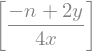

In [16]:
x, y = sp.symbols('x y', real=True)
k, n = sp.symbols('k n', positive=True)
eq = sp.Eq(y, 2*k*x + n/2)

sol = sp.solve(eq, k)
sol

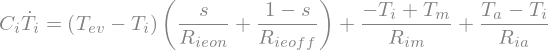

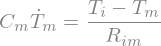

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [3]:
T_i, T_m, T_a, T_ev = sp.symbols("T_i T_m T_a T_ev", real=True)
R_ia, R_im, R_ie_on, R_ie_off = sp.symbols("R_ia R_im R_ie_on R_ie_off", positive=True)
C_i, C_m = sp.symbols("C_i C_m", positive=True)
s = sp.Symbol("s", nonnegative=True)   # compressor on-fraction
dT_i, dT_m = sp.symbols(r"\dot{T}_i \dot{T}_m")

g = s / R_ie_on + (1 - s) / R_ie_off
balances = [
    sp.Eq(C_i * dT_i, (T_a - T_i) / R_ia + (T_m - T_i) / R_im + g * (T_ev - T_i)),
    sp.Eq(C_m * dT_m, (T_i - T_m) / R_im),
]
for b in balances:
    display(b)

sol = sp.solve(balances, [dT_i, dT_m], dict=True)[0]
f = sp.Matrix([sp.expand(sol[dT_i]), sp.expand(sol[dT_m])])
show(r"\dot{T}_i", f[0]); show(r"\dot{T}_m", f[1])

## State-space form

The balances are linear in the states $x = [T_i, T_m]$ and in the inputs $d = [T_a, T_{ev}]$, so

$$\dot x = A(s)\, x + E(s)\, d, \qquad A = \frac{\partial f}{\partial x},\; E = \frac{\partial f}{\partial d}.$$

There is no control input $u$: the measured coil temperature replaces the cooling power.

In [3]:
x = sp.Matrix([T_i, T_m])
d = sp.Matrix([T_a, T_ev])
A = f.jacobian(x)
E = f.jacobian(d)

show(r"x", x); show(r"d", d)
show(r"A(s)", A)
show(r"E(s)", E)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [4]:
assert sp.simplify(A * x + E * d - f) == sp.zeros(*f.shape)
print("A x + E d == f  ✓")

A x + E d == f  ✓


## Time constants, steady state and limits

The two time constants are $\tau_{1,2} = -1/\lambda_{1,2}(A(s))$; they differ between the compressor-off ($s=0$) and
compressor-on ($s=1$) phases because $g(s)$ enters the $T_i$ row. In steady state no heat flows into the mass, so
$T_{m,ss} = T_{i,ss}$, the conductance-weighted mean of $T_a$ and $T_{ev}$. The limit $R_{im} \to \infty$ (mass decoupled)
reduces the model to the 1R1C_evin model with $C_i$; $R_{im} \to 0$ lumps the mass with the air ($C_i + C_m$).

In [5]:
lam = list(A.eigenvals().keys())
for k, l in enumerate(lam, 1):
    show(rf"\lambda_{k}", sp.simplify(l))

ss = sp.solve(list(f), [T_i, T_m], dict=True)[0]
show(r"T_{i,ss}", sp.simplify(ss[T_i])); show(r"T_{m,ss}", sp.simplify(ss[T_m]))

show(r"\lambda_1 \lambda_2 = \det A", sp.simplify(A.det()))
show(r"\lambda_1 + \lambda_2 = \operatorname{tr} A", sp.simplify(A.trace()))

# R_im -> oo: the T_i row becomes the 1R1C_evin balance with C_i
show(r"\lim_{R_{im}\to\infty} \dot{T}_i", sp.limit(f[0], R_im, sp.oo))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Discretization (as implemented in the toolbox)

With the inputs held constant over each step (zero-order hold), the exact one-step map at on-fraction $s_k$ is

$$x_k = A_d(s_k)\, x_{k-1} + B_d(s_k)\, d_k, \qquad A_d = e^{A\,\Delta t}, \qquad B_d = \int_0^{\Delta t} e^{A \sigma}\,d\sigma\; E,$$

which `rctoolbox.models.discretization.zoh_discretize` evaluates with the augmented-matrix exponential

$$\exp\!\left(\begin{bmatrix} A & E \\ 0 & 0 \end{bmatrix}\Delta t\right) = \begin{bmatrix} A_d & B_d \\ 0 & I \end{bmatrix}.$$

$s$ is rounded to `S_LEVELS = 11` levels, so `get_discrete_matrices` computes 11 matrix pairs per parameter set and $\Delta t$
(cached). The forward-Euler option steps $x_k = x_{k-1} + \Delta t\,(A x_{k-1} + E d_k)$ and is stable only for
$\Delta t < 2\tau_{\min}$; with the fans on $\tau_{\min}$ is of the order of a minute, so Euler is a cross-check only.

## Check against the toolbox implementation

The symbolic matrices are evaluated for random parameter values and on-fractions and compared with `calc_matrices(s)` of the
model class. The forecast is then compared with the network implementation `Freezer2R2C_IM_EVIN` and with a fine-step
forward-Euler simulation.

In [6]:
from rctoolbox.models.rc.freezer_models.two_r2c_im_evin.model import TwoR2CInternalMassEvIn

rng = np.random.default_rng(0)
model = TwoR2CInternalMassEvIn()
for _ in range(5):
    p = {"R_ia": rng.uniform(1e-3, 1), "C_i": rng.uniform(1e3, 1e7), "R_im": rng.uniform(1e-4, 1),
         "C_m": rng.uniform(1e4, 1e8), "R_ie_on": rng.uniform(1e-4, 1), "R_ie_off": rng.uniform(1e-3, 10)}
    model.set_params(p)
    for sv in (0.0, 0.5, 1.0):
        A_num, E_num = model.calc_matrices(sv)
        subs = {R_ia: p["R_ia"], C_i: p["C_i"], R_im: p["R_im"], C_m: p["C_m"],
                R_ie_on: p["R_ie_on"], R_ie_off: p["R_ie_off"], s: sv}
        for name, S, N in [("A", A, A_num), ("E", E, E_num)]:
            assert np.allclose(np.array(S.subs(subs), dtype=float), N, rtol=1e-12, atol=0), name
print("symbolic A, E == TwoR2CInternalMassEvIn.calc_matrices(s)  ✓")

symbolic A, E == TwoR2CInternalMassEvIn.calc_matrices(s)  ✓


In [7]:
from rctoolbox.models.rc.freezer_models.fz_2r2c_im_evin.model import Freezer2R2C_IM_EVIN

p = {"R_ia": 0.05, "C_i": 2e5, "R_im": 0.01, "C_m": 2e6, "R_ie_on": 0.005, "R_ie_off": 0.1}   # plausible freezer values
model.set_params(p)
ref = Freezer2R2C_IM_EVIN(); ref.set_params(p)
print("time constants off (min):", np.round(model.time_constants / 60, 2),
      "| on (min):", np.round(model.time_constants_on() / 60, 2))

B, N, dt, fine = 3, 61, 120.0, 1000
on = (rng.random((B, N)) > 0.6).astype(float)
T_a = 5 + rng.normal(size=(B, N))
T_ev = np.where(on > 0, -26.0, -15.0) + rng.normal(size=(B, N))
y0 = np.full((B, 2), -18.0)
t = np.arange(N) * dt

z = model.forecast_temperature(y0, t, T_a, T_ev, on, integration="zoh")
r = ref.forecast_temperature(y0, t, integration="zoh", T_a=T_a, T_ev=T_ev, on=on)
print("max |standalone - network| (K):", np.abs(z - r).max())

rep = lambda a: np.concatenate([a[:, :1], np.repeat(a[:, 1:], fine, axis=1)], axis=1)
e = model.forecast_temperature(y0, np.arange((N - 1) * fine + 1) * dt / fine, rep(T_a), rep(T_ev), rep(on),
                               integration="euler")[:, ::fine]
print("max |ZOH - fine Euler| over 2 h (K):", np.abs(z - e).max())

time constants off (min): [  24.19 1531.37] | on (min): [ 10.31 489.69]
max |standalone - network| (K): 0.0


max |ZOH - fine Euler| over 2 h (K): 0.00017775881070392074
